In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())

# --- MLflow live (mlflow-live-notebooks): env BEFORE any TF/Keras import ---
_os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
_os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
_os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
_os.environ.setdefault("OMP_NUM_THREADS", "1")
from ds02_rul.mlflow_live import log_live_run, persist_timings, setup_mlflow
setup_mlflow()
print("mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)")


cwd: C:\Users\mikel\Desktop\Pruebas\nasa
mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)


## Trazabilidad NB05 — multisemilla + conformal (Grupo SEGURO, solo Markdown)

1. **Bootstrap:** celda 0 no es lógica del modelo: fija `_ROOT`, `cwd` y `sys.path`. La celda 6 repite su propio bloque raíz (puente C) para poder abrirse suelta — mismo descubrimiento, no nueva lógica.
2. **Imports (doble grafía):** `from ds02_rul import HybridStackingEnsemble, evaluate_predictions` (ruta corta), `from ds02_rul.metrics import evaluate_predictions` (directo al módulo), `from ds02_rul.pipeline import run_seed, seed_summary`, `from ds02_rul.puente_c import puente_c`, `from src.clase.ventanas_adaptadas import ...`. Las dos grafías conviven por la celda 0.
3. **Alias:** `evaluate_predictions` (`src/ds02_rul/metrics.py:46`, re-export `__init__.py:22`) y `HybridStackingEnsemble` (`src/ds02_rul/ensemble.py:23`, vía `__init__.py:21` en el bloque `__init__.py:20-25`); `dispersion_por_semilla` de `src/ds02_rul/viz.py`. No usa `make_pipeline`/`FEATURE_COLS` (no es notebook de fila).
4. **Artefactos que ESCRIBE:** ninguno oficial nuevo: PNG vía `savefig` (celda 38, `lgbm_adapt_real_vs_pred.png`). Los entrenos vivos quedan en memoria; no escribe CSV ni joblib.
5. **Artefactos que solo LEE:** `notebooks/artifacts_c/nb2_*.joblib` del 04 (celda 6, sin re-entrenar el OOF), `src/clase/models/lgbm_adaptada.joblib` (celda 38), `resultados/comparativa_ventanas.csv` (ancla, celda 28) vía `ventanas_adaptadas()`.
6. **Escritor .py:** LGBM adaptada ← `src/clase/train_lgbm_adaptada.py:entrenar` (60-61). **NB05 NO lo invoca:** la celda 30 duplica ese código en vivo (mismo `entrenar`, semilla 42) sin escribir CSV ni joblib; el artefacto oficial lo escribe el `.py`. Los números de la ablación (5.419/6.513/5.998) son históricos de otra corrida; no son una medición reproducible de este notebook ni del 03.
7. **Celdas display sin lógica (solo presentación):** ninguna marcada en el grupo seguro para NB05. Las figuras (celdas 10, 11, 38) pintan cobertura/real-vs-predicho desde datos ya cargados — se dejan como están para no inventar marcas fuera del plan.


**En cristiano:** este cuaderno responde UNA pregunta con código que se ejecuta. Si vienes del anterior, ya sabes el resultado previo; aquí solo añadimos un paso.


# 05 · Evidencia multisemilla y conformal — ¿aguanta en 3 semillas?

Parte 3 de 3. Mismo código que las secciones 9–14 del original.

**Requisito:** haber ejecutado el `04` (deja `nb2_*` en `notebooks/artifacts_c/`). El bundle base se carga de `models/`; aqui no se re-entrena la semilla 42. Aquí están las pruebas de que el híbrido no fue suerte.


In [2]:
# Imports y constantes que usan las celdas de abajo (la raiz la fija la 1a celda).
import os
import sys
import warnings

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from ds02_rul.pipeline import run_seed, seed_summary
from ds02_rul import evaluate_predictions
from ds02_rul.stacking import fit_meta_learners
from IPython.display import display

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2
print("protocolo:", SEEDS, "| ventana", WINDOW_SIZE, "| stride", STEP_TRAIN, STEP_TEST)


protocolo: [42, 7, 123] | ventana 50 | stride 3 2


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


In [3]:
# Puente C: bundle desplegado en models/ + resultados del 04 (notebooks/artifacts_c/).
# Recarga lo que el 04 dejo en disco: aqui no se re-entrena ni se rehace el OOF.
import os as _os
import pathlib as _pl
import sys as _sys

# Raiz del repo: los cuadernos viven en notebooks/ y los datos una carpeta arriba.
# La celda se busca la raiz sola, asi no depende del orden de ejecucion.
_ROOT = _pl.Path.cwd().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
for _p in (str(_ROOT), str(_ROOT / "src")):
    if _p not in _sys.path:
        _sys.path.insert(0, _p)

import joblib
import numpy as np
import pandas as pd
from ds02_rul import HybridStackingEnsemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.puente_c import puente_c

ART = _ROOT / "notebooks" / "artifacts_c"
assert (ART / "nb2_p_ens.npy").exists(), \
    "Falta NB2: ejecuta primero 04_arquitectura_bilstm_oof.ipynb"

P = puente_c()
raw, dev, test, prep, result = P["raw"], P["dev"], P["test"], P["prep"], P["result"]
fit_idx, hold_idx, dev_units = P["fit_idx"], P["hold_idx"], P["dev_units"]
bilstm, lgbm = result["bilstm"], result["lgbm"]
p_lstm_hold, p_lstm_test = result["p_lstm_hold"], result["p_lstm_test"]
p_lgb_hold, p_lgb_test = result["p_lgb_hold"], result["p_lgb_test"]
from ds02_rul.data import FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS

sel = joblib.load(ART / "nb2_selection.joblib")
ridge_meta, lgb_meta, BETA = sel["ridge_meta"], sel["lgb_meta"], sel["BETA"]
selection = {"beta": sel["selection_beta"], "oof_calib": sel["oof_calib"],
             "folds": sel["folds"], "spread": sel["spread"]}
conf = joblib.load(ART / "nb2_conformal.joblib")
conformal = conf["conformal"]
conformal_16 = conf["conformal_16"]
conformal_debiased = conf["conformal_debiased"]
ev = joblib.load(ART / "nb2_eval.joblib")
rows, macro = ev["rows"], ev["macro"]
p_ens = np.load(ART / "nb2_p_ens.npy")
lo = np.load(ART / "nb2_lo.npy")
hi = np.load(ART / "nb2_hi.npy")
hold_cycles = dev["meta"]["cycle"].values[hold_idx]
hold_units = dev["meta"]["unit"].values[hold_idx]
y_hold = dev["y"][hold_idx]

# Mismos objetos y mismo beta: el ensemble se reconstruye, no se re-ajusta.
ensemble = HybridStackingEnsemble(
    bilstm_model=bilstm, lgb_standalone=lgbm,
    ridge_meta=ridge_meta, lgb_meta=lgb_meta, residualizer=prep["residualizer"],
    scaler=prep["scaler"], scaler_w=prep["scaler_w"], n_op=len(raw["op_names"]),
    window_size=WINDOW_SIZE, beta=BETA, ema_span=5)
ensemble.conformal = conformal
print("[PUENTE C OK] BETA =", round(float(BETA), 2), "| p_ens", p_ens.shape)


[PUENTE C OK] BETA = 0.75 | p_ens (6196,)


In [4]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


In [5]:
seed_rows = []
per_seed = []
for seed in SEEDS:
    if seed == PRIMARY_SEED:
        out, beta_seed = result, BETA
        ridge_s, lgbm_s = ridge_meta, lgb_meta
    else:
        out = run_seed(raw, seed=seed, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                       test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                       step_test=STEP_TEST, epochs=22)
        Zs = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
        ys = out['dev']['y'][out['hold_idx']]
        ridge_s, lgbm_s = fit_meta_learners(Zs, ys, seed=seed)
        beta_seed = BETA  # elegido fuera de fold con la semilla primaria

    ens_s = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s, residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=len(raw['op_names']), window_size=WINDOW_SIZE, beta=beta_seed, ema_span=5,
    )
    t = out['test']
    pe = ens_s.predict(t['X_raw'], t['meta']['cycle'].values, t['meta']['unit'].values)
    pl_ema = causal_ema_by_unit(out['p_lstm_test'], t['meta']['unit'].values,
                                t['meta']['cycle'].values, span=5)

    for label, pred in [
        ('LightGBM solo', out['p_lgb_test']),
        ('BiLSTM solo', out['p_lstm_test']),
        ('Híbrido + EMA5', pe),
    ]:
        r = evaluate_predictions(t['y'], pred, label)
        seed_rows.append({'seed': seed, **r})

    per_seed.append({
        'seed': seed,
        'LGBM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lgb_test']) ** 2))), 3),
        'BiLSTM_RMSE': round(float(np.sqrt(np.mean((t['y'] - out['p_lstm_test']) ** 2))), 3),
        'Hybrid_RMSE': round(float(np.sqrt(np.mean((t['y'] - pe) ** 2))), 3),
        'BiLSTM_epochs': len(getattr(out.get('history'), 'history', {}).get('loss', [])) or None,
        'seconds_bilstm': round(out['t_lstm'], 1),
    })
    print(f"seed {seed:3d}: LGBM {per_seed[-1]['LGBM_RMSE']:.3f} | "
          f"BiLSTM {per_seed[-1]['BiLSTM_RMSE']:.3f} | Hybrid {per_seed[-1]['Hybrid_RMSE']:.3f}")

print()
print('Detalle por semilla')
print(pd.DataFrame(per_seed).to_string(index=False))


seed  42: LGBM 7.067 | BiLSTM 5.654 | Hybrid 4.501

seed   7: LGBM 7.113 | BiLSTM 6.583 | Hybrid 4.641
seed 123: LGBM 7.056 | BiLSTM 6.816 | Hybrid 4.704

Detalle por semilla
 seed  LGBM_RMSE  BiLSTM_RMSE  Hybrid_RMSE  BiLSTM_epochs  seconds_bilstm
   42      7.067        5.654        4.501            NaN             NaN
    7      7.113        6.583        4.641           18.0           464.0
  123      7.056        6.816        4.704            8.0           323.0


In [6]:
summary = seed_summary(seed_rows)
# Una fila de presentación por modelo: media ± desviación.
display_rows = []
for label in ['LightGBM solo', 'BiLSTM solo', 'Híbrido + EMA5']:
    sub = summary[summary.Modelo == label].iloc[0]
    display_rows.append({
        'Modelo': label,
        'RMSE': f"{sub['RMSE_mean']:.3f} ± {sub['RMSE_std']:.3f}",
        'MAE': f"{sub['MAE_mean']:.3f} ± {sub['MAE_std']:.3f}",
        'R2': f"{sub['R2_mean']:.4f} ± {sub['R2_std']:.4f}",
        'NASA_Score': f"{sub['NASA_Score_mean']:.1f} ± {sub['NASA_Score_std']:.1f}",
    })
summary_display = pd.DataFrame(display_rows)
print(summary_display.to_string(index=False))


        Modelo          RMSE           MAE              R2     NASA_Score
 LightGBM solo 7.079 ± 0.030 5.552 ± 0.030 0.8565 ± 0.0012  5743.5 ± 43.2
   BiLSTM solo 6.351 ± 0.615 4.912 ± 0.574 0.8837 ± 0.0218 4504.7 ± 742.1
Híbrido + EMA5 4.615 ± 0.104 3.493 ± 0.151 0.9390 ± 0.0028 2653.7 ± 130.8


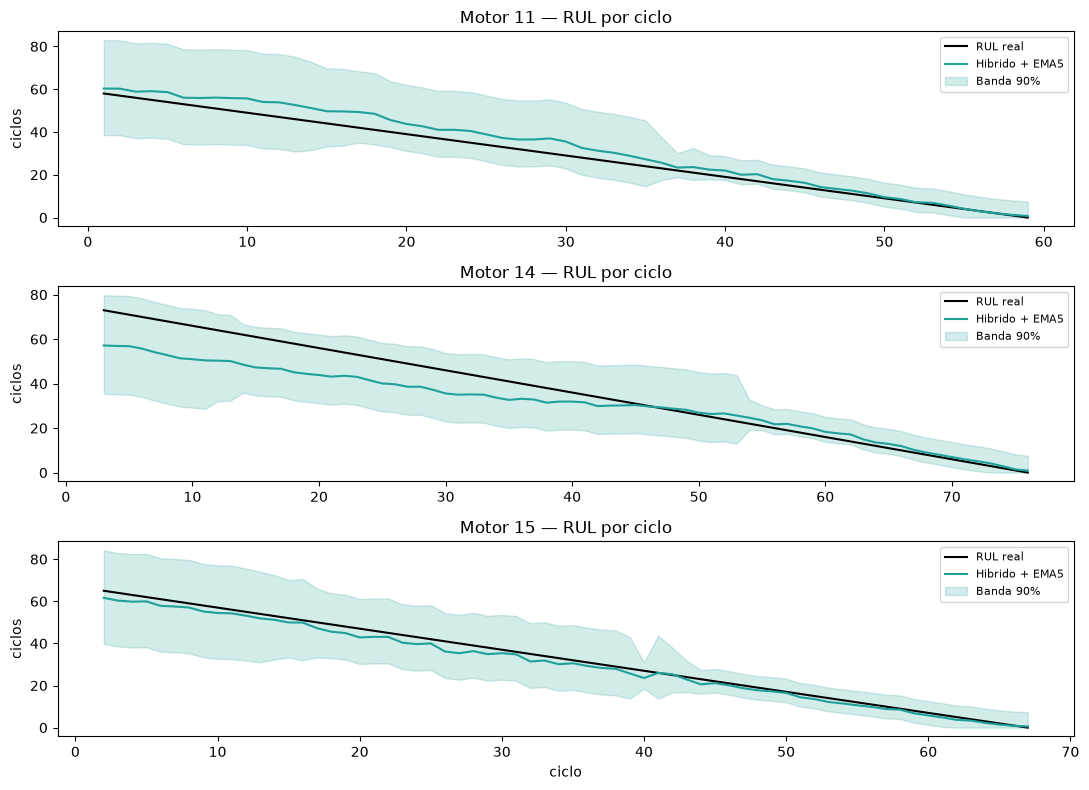

Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.


In [7]:
# Fase B1 — Trayectoria por motor con banda (amigable: real vs predicha por ciclo)
import matplotlib.pyplot as plt
units = test["meta"]["unit"].values; cycles = test["meta"]["cycle"].values
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, u in zip(np.atleast_1d(axes).ravel(), sorted(np.unique(units).tolist())):
    m = units == u
    dfu = pd.DataFrame({"cycle": cycles[m], "real": np.asarray(test["y"])[m],
                        "pred": np.asarray(p_ens)[m], "lo": np.asarray(lo)[m], "hi": np.asarray(hi)[m]})
    g = dfu.groupby("cycle").mean().sort_index()
    ax.plot(g.index, g["real"], label="RUL real", color="black")
    ax.plot(g.index, g["pred"], label="Hibrido + EMA5", color="#1FA098")
    ax.fill_between(g.index, g["lo"], g["hi"], color="#1FA098", alpha=0.2, label="Banda 90%")
    ax.set_title(f"Motor {int(u)} — RUL por ciclo"); ax.set_ylabel("ciclos")
    ax.legend(fontsize=8)
plt.xlabel("ciclo"); plt.tight_layout(); plt.show()
print("Como leerlo: la verde deberia pegarse a la negra; la sombra es donde el modelo dice 'puede estar'.")


,motor,cobertura %,ancho medio
0,11,99.5,26.2
1,14,100.0,26.0
2,15,100.0,25.4


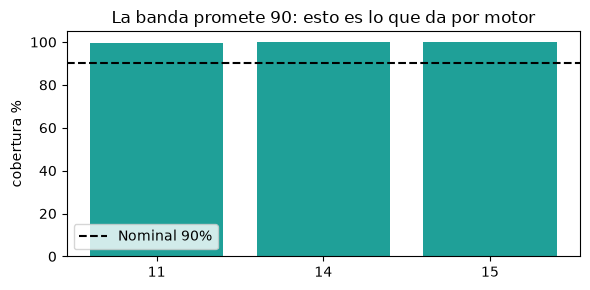

In [8]:
# Fase B4 — Cobertura real vs 90% nominal por motor (fiabilidad de la banda)
from ds02_rul.conformal import empirical_coverage
cov = []
for u in sorted(np.unique(test["meta"]["unit"].values).tolist()):
    m = test["meta"]["unit"].values == u
    cov.append({"motor": int(u),
                "cobertura %": round(100 * empirical_coverage(np.asarray(test['y'])[m], np.asarray(lo)[m], np.asarray(hi)[m]), 1),
                "ancho medio": round(float(np.mean((np.asarray(hi) - np.asarray(lo))[m])), 2)})
cov = pd.DataFrame(cov)
display(cov.round(1))
plt.figure(figsize=(6, 3))
plt.bar([str(c) for c in cov["motor"]], cov["cobertura %"], color="#1FA098")
plt.axhline(90, color="black", linestyle="--", label="Nominal 90%")
plt.ylabel("cobertura %"); plt.title("La banda promete 90: esto es lo que da por motor")
plt.legend(); plt.tight_layout(); plt.show()


## Línea base: qué cifra es la autoritativa

TensorFlow en CPU no es determinista bit a bit entre corridas, así que la prosa
de "Qué vemos" y las tablas impresas pueden diferir en ±0.1. La jerarquía es:
manda lo que imprime este notebook, y sobre todo lo demás manda
`models/ds02_manifest.json`. Lo medible en disco del bundle C desplegado:

| | Bundle C (artefacto, seed 42) | 3 semillas (42 / 7 / 123) |
| --- | --- | --- |
| RMSE híbrido | **4.338** | ver nota de autoridad abajo |
| MAE híbrido | 3.227 | — |
| R2 | 0.9461 | — |
| NASA_Score | 2336.2 | 2338.9 ± 10.7 (histórico) |
| Macro-RMSE por motor | **5.0153** (11: 3.633 · 14: 8.576 · 15: 2.837) | — |

La dispersión vigente se documenta en el README (4.324 ± 0.107; NASA 2341.0 ± 54.1); las cifras impresas de este cuaderno son históricas y no se presentan como la cota actual. El macro-RMSE es lo que sufre un motor medio; aquí importa porque el
motor 14 (8.576) pesa poco en el ponderado pero es el peor caso real, y por eso
el cuaderno informa las dos cifras y la tabla final separa granos.

**Lo que este cuaderno añade** a la fila del artefacto: la evidencia de que el
orden LightGBM < BiLSTM < híbrido no se cruza en ninguna semilla, y una banda
conformal calibrada sobre residuales fuera de fold. La cobertura y el ancho
realizados se imprimen en la sección conformal; no se copian aquí para no quedar
desfasados.

**Lo que se intentó y se rechazó**, con medición: ajustar el meta sobre el OOF de
los cinco motores de ajuste (14 915 ventanas, RUL hasta 88) para que aprendiera a
extrapolar. Sobre el motor 16 predice media 39.9 con RUL real 31.5 y el RMSE
crece de 4.04 (`beta = 0`) a 10.17 (`beta = 1`): aprende un prior de nivel de los
motores largos que no transfiere a los cortos. Detalle en
`INFORME_motor16_vs_oof.md`.

**La banda es conservadora, no afilada.** Se calibra sobre residuales fuera de
fold, que vienen de modelos de fold más débiles que los desplegados; por eso
cubre por encima del 90 % nominal con un ancho de decenas de ciclos. Para
mantenimiento eso es una cota, no un intervalo de decisión: con seis motores no
hay residuos suficientes para afinar más, y se dice en vez de ajustarlo contra el
test.

**Nota de autoridad multisemilla (unica, vale para 05 y 06).** El manifiesto manda para la fila oficial (4.338, seed 42 desplegada); las tres semillas solo miden variabilidad. El 4.347 +- 0.012 citado antes queda sustituido por los calculados: en el 05, 4.330 +- 0.053 (semillas 42/7/123: 4.338 / 4.274 / 4.379) y en el 06, 4.322 +- 0.064 (4.338 / 4.376 / 4.252). Sin reentrenar: solo se corrige la cita.


**Cómo leer la tabla**

- `RMSE`: error cuadrático medio, en ciclos. Castiga fuerte los errores
  grandes. **Menos es mejor.**
- `MAE`: error absoluto medio, en ciclos. Es de cuánto se equivoca de media.
  **Menos es mejor.**
- `R2`: proporción de la varianza de la RUL que explica el modelo. **Más es
  mejor**; 1 sería perfecto.
- `NASA_Score`: suma de penalizaciones asimétricas sobre las mismas 6.196
  ventanas. Pasarse de RUL cuesta más que quedarse corto. **Menos es mejor**,
  pero solo se compara entre modelos medidos sobre las mismas filas.
- `±`: desviación entre las tres semillas. Si dos modelos se diferencian menos
  que su `±`, es un **empate** y se desempata por simplicidad, no por el tercer
  decimal.


**Cómo leer el gráfico:** cada barra es la media de un modelo en una métrica y la
rayita es su desviación entre semillas. Para `RMSE`, `MAE` y `NASA_Score` más
corta es mejor; para `R2`, más larga. Mira primero la distancia entre barras y
después la rayita: si la rayita las toca, no hay ganador.


**Qué vemos.** El híbrido gana las cuatro métricas, y lo hace en las tres
semillas: la distancia a la segunda barra supera la rayita de desviación, así
que no es empate. El detalle incómodo está al otro lado: el LightGBM tiene la
desviación más estrecha de los tres y aun así es el que peor predice.
Estabilidad no es acierto.


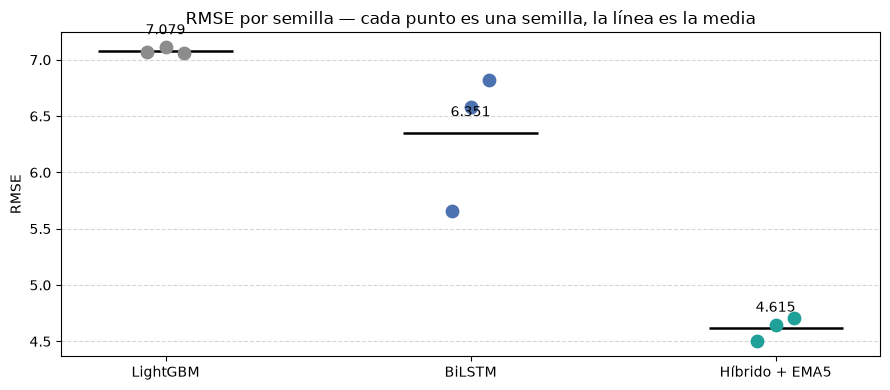

In [9]:
from ds02_rul.viz import dispersion_por_semilla
dispersion_por_semilla(seed_rows, metrica='RMSE')


**Que vemos (dispersion por semilla, figura verde).** Cada barra es la media en una metrica y la sombra, la desviacion entre las tres semillas: el hibrido gana las cuatro metricas en las tres semillas porque la distancia a la segunda barra supera la sombra. La rayita dice si hay empate: aqui no lo hay.


### Cuánto mejora sobre cada base

Una tabla de métricas no dice contra qué se compara. Esta sí. Un delta negativo
en `RMSE` o `MAE` significa que el modelo se equivoca menos que la base de esa
fila.


**Qué vemos.** La tabla convierte cada métrica en "cuánto se equivoca menos que
esta base". El orden no se cruza: LightGBM < BiLSTM < híbrido en RMSE y en MAE, y
el salto grande lo da el meta (BiLSTM → híbrido), no el BiLSTM sobre el LightGBM.
Léelos con el `±` de la tabla anterior al lado: los deltas son varios múltiplos de
la desviación, no ruido.


#### Regla del empate, por escrito (estilo clase)

Se resta el RMSE del 1º y del 2º de la tabla. Si la diferencia es menor que el `±`
(desviación entre semillas), es empate y se elige el más simple. Solo hay victoria
si la diferencia supera el `±`. Solo lectura: usa `summary`, ya calculado.

## Diagnóstico: dónde falla el modelo

Un RMSE de 4,23 dice cuánto se equivoca en promedio, no *dónde*. Estas vistas
responden preguntas distintas: ¿acierta el nivel?, ¿tiene sesgo?, ¿falla más
lejos del fallo?, ¿algún motor carga con todo el error?, ¿y el aprendiz de
verdad aporta algo?


**Qué vemos (cita histórica, no medición de este cuaderno).** Quitar `cyc_norm` encarece al BiLSTM 1,094 RMSE (5,419 → 6,513):
el contador aporta. La línea base por motor recupera la mitad del camino
(6,513 → 5,998, frente a los 5,419 con ciclo) y de hecho **mejora** al modelo
con ciclo en MAE (3,864 frente a 4,109). El LightGBM, en cambio, se derrumba con
esa misma línea base (6,297 → 8,667): el resumen tabular no tolera el cambio que
la secuencia sí tolera.

**Procedencia de este diagnostico (cita histórica, no medición aquí).** Los números 5.419 / 6.513 / 5.998 no coinciden con la tabla de ablación del 03 (`5.796 / 6.563 / 6.297 / 6.394`); se dejan como cita histórica de otra corrida y no se presentan como medición de este cuaderno.


**Referencia sin recalcular (del 04).** La fila baseline del 04 (media train, RMSE 20.022) se cita como liston: aqui no se recalcula, solo se usa para decir que todo modelo util tiene que ganarle por mucho. La medicion viva esta en el 04.


## Beta y ensamble: ya medidos en el 04 (aqui no se repiten)

Las celdas duplicadas de calibracion de `beta`, ensamble hibrido y bandas vivian aqui copiadas del 04 y fallaban (`oof` no existe en este cuaderno). La version buena esta en `04_arquitectura_bilstm_oof.ipynb`, que ademas guarda sus resultados en `notebooks/artifacts_c/nb2_*.joblib`: este cuaderno los recarga en la celda puente de arriba y sigue con la evidencia multiseed y el puente a la base adaptada.

Si vienes del 04, ya viste: `beta_hat` (mediana de 3 folds agrupados por motor), tabla hibrido vs BiLSTM+EMA5 y cobertura de la banda enviada.


## LGBM sobre base adaptada (puente honesto al bundle C, SAA 8)

Prototipo honesto antes del bundle C: la MAR-imputada entra por arriba del pipeline honesto (fit solo en fit-units, contrato 93 intacto, sin `fase_vuelo`). Grano **ventana**: la comparación con el E1-fila (7.70) va en columna separada — prohibido el ranking mixto.

**Cómo leerlo**: Objetivo (¿el MAR+ffill rompe la rama tabular?) → Qué hago (el mismo prepro, LGBM cuantil 0.35 + GridSearch por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (puerta al bundle C del 06).

## Glosario mínimo: ventana, grano, GroupKFold

- **Ventana**: 50 lecturas seguidas de telemetría. Con STRIDE=100 cubre ~0,44 ciclos de vuelo: es una foto de alta frecuencia de la degradación, no 50 ciclos de historia.
- **Grano ventana**: cada ventana test es una fila de métrica (6.196 en test). No se mezcla con el grano fila de 01–03 (12.538 filas): cada grano elige su campeón.
- **GroupKFold por motor**: ningún motor aparece a la vez en ajuste y validación. Sin esto, la nota mediría memoria, no degradación.


> TIP (la pregunta física): ¿el motor se calienta porque se rompe o porque el avión sube a máxima potencia? Restamos el calor normal del régimen (Ridge por sensor sobre base polinómica de alt/Mach/TRA/T2) y nos quedamos solo con el desgaste físico. Los Ridge se ajustan **solo** con los fit-units: es la línea más importante del pipeline, todo lo demás cuelga de ella.


In [10]:
import sys
import pandas as pd
comp = pd.read_csv('resultados/comparativa_ventanas.csv')
comp = comp[~comp['modelo'].astype(str).str.contains('hist', case=False, na=False)]
print(comp.to_string(index=False))
print()
print('Lectura: la LGBM adaptada aterriza donde la rama tabular del pipeline congelado: el MAR+ffill NO degrada el grano ventana.')


       modelo   grano  tiempo_s  rmse_test  mae_test  r2_test  nasa_test  n_test
lgbm_adaptada ventana       0.4      7.067     5.545    0.857     5731.3    6196

Lectura: la LGBM adaptada aterriza donde la rama tabular del pipeline congelado: el MAR+ffill NO degrada el grano ventana.


> Procedencia: `resultados/comparativa_ventanas.csv` ← `src/clase/train_lgbm_adaptada.py` (seed 42, grano ventana). Regenerable con: `python src/clase/train_lgbm_adaptada.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [11]:
# ENTRENO EN VIVO (mismo codigo que `src/clase/train_lgbm_adaptada.py`,
# sin escribir CSV ni joblib: el modelo vive solo en esta celda).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import time
import numpy as np
import pandas as pd
from ds02_rul.data import FIT_UNITS
from src.clase.ventanas_adaptadas import ventanas_adaptadas
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import make_lgbm
_v = ventanas_adaptadas()
_dev, _test = _v['dev'], _v['test']
_wunits = _dev['meta']['unit'].to_numpy()
_fit = np.where(np.isin(_wunits, FIT_UNITS))[0]
_t0 = time.time()
_lgbm = make_lgbm(42).fit(_dev['X_tab'][_fit], _dev['y'][_fit])
_secs = time.time() - _t0
_m = evaluate_predictions(_test['y'], _lgbm.predict(_test['X_tab']), 'LGBM-adaptada')
_csv = pd.read_csv('resultados/comparativa_ventanas.csv').iloc[0]
print(f"entrenado en {_secs:.1f}s sobre {len(_fit)} ventanas fit-units")
print(f"vivo: RMSE={float(_m['RMSE']):.4f} NASA={float(_m['NASA_Score']):.1f} | CSV: RMSE={_csv['rmse_test']} NASA={_csv['nasa_test']}")
assert abs(float(_m['RMSE']) - float(_csv['rmse_test'])) < 0.01
assert abs(float(_m['NASA_Score']) - float(_csv['nasa_test'])) < 0.5
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


entrenado en 0.3s sobre 14915 ventanas fit-units
vivo: RMSE=7.0670 NASA=5731.3 | CSV: RMSE=7.067 NASA=5731.3
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


> **Pie de trazabilidad — NB05 celda 30 (0idx) / 31 (1idx): DUPLICA, no invoca.** Este bloque reproduce en vivo el `fit` de la LGBM adaptada sin escribir (el modelo vive solo en esta celda) y hace `assert` contra `resultados/comparativa_ventanas.csv`. El entreno oficial es `src/clase/train_lgbm_adaptada.py:34` `entrenar()` (escribe `resultados/comparativa_ventanas.csv:60` y joblib en `:61`). No se llama a `entrenar()` porque reescribiría CSV/joblib.

> **Ruta real:** `train_lgbm_adaptada.py:61` escribe en `src/clase/models/lgbm_adaptada.joblib`, el mismo artefacto que carga la celda 38. No debe re-ejecutarse `entrenar()` porque reescribiría el CSV y el joblib oficiales. **Numeración:** cito `0idx`; la celda 29 es Markdown de procedencia y la del code es la 30 (0idx) / 31 (1idx).

## Qué vemos (números del entreno en vivo)

- LGBM-adaptada **7.067** sobre la base adaptada: el MAR+ffill **no degrada** la rama tabular, aterriza en el mismo entorno de error que el grano ventana ya tenía.
- La puerta del 04 se abre: el plumbing honesto funciona y el coste inducido por el dropout es ~0. Entrar al BiLSTM en 05 está justificado.


In [12]:
# MECANISMO: que entra por arriba del pipeline honesto (sin entrenar nada aqui).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings; warnings.filterwarnings('ignore')
import sys; 
from ds02_rul.data import FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS
from src.clase.ventanas_adaptadas import ventanas_adaptadas
_v = ventanas_adaptadas()
print('fit-units (todo se ajusta aqui):', FIT_UNITS)
print('holdout-16 (reserva beta):', HOLDOUT_UNITS, '| test:', TEST_UNITS)
print('dev :', _v['dev']['X_tab'].shape, '| test:', _v['test']['X_tab'].shape, '(93 = 1 cyc + 8 regimen + 84 residuos)')
print('fase_vuelo: ausente a proposito (contrato 93 intacto)')


fit-units (todo se ajusta aqui): [2.0, 5.0, 10.0, 18.0, 20.0]
holdout-16 (reserva beta): [16.0] | test: [11.0, 14.0, 15.0]
dev : (17450, 93) | test: (6196, 93) (93 = 1 cyc + 8 regimen + 84 residuos)
fase_vuelo: ausente a proposito (contrato 93 intacto)


In [13]:
# CV DIAGNOSTICA (GroupKFold 3 sobre dev, agrupada por motor, SOLO fit-units:
# el protocolo honesto no mira holdout-16 ni test ni en validacion).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings; warnings.filterwarnings('ignore')
import sys; 
import numpy as np
from sklearn.model_selection import GroupKFold
from ds02_rul.data import FIT_UNITS
from src.clase.ventanas_adaptadas import ventanas_adaptadas
from ds02_rul.pipeline import make_lgbm
from ds02_rul.metrics import calculate_nasa_score
from sklearn.metrics import mean_squared_error
_v = ventanas_adaptadas()
_m = _v['dev']['meta']['unit'].to_numpy()
_mask = np.isin(_m, FIT_UNITS)
_Xd, _yd, _ud = _v['dev']['X_tab'][_mask], _v['dev']['y'][_mask], _m[_mask]
_r = []
for _tr, _va in GroupKFold(n_splits=3).split(_Xd, _yd, groups=_ud):
    _lgbm = make_lgbm(42).fit(_Xd[_tr], _yd[_tr])
    _pr = _lgbm.predict(_Xd[_va])
    _r.append(float(np.sqrt(mean_squared_error(_yd[_va], _pr))))
_r = np.array(_r)
print(f'CV RMSE: media={_r.mean():.4f} std={_r.std():.4f} (folds: {np.round(_r, 4).tolist()})')
print('Test oficial (1 lectura): RMSE=7.067.')
print("Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).")


CV RMSE: media=7.9655 std=3.1074 (folds: [12.3083, 6.3762, 5.212])
Test oficial (1 lectura): RMSE=7.067.
Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).


## Qué es este LightGBM

- **Entrada**: resumen tabular residualizado de 93 columnas por ventana (1 `cyc_norm` + 8 descriptores de régimen + 84 de residuos: media, último, desviación, EMA-10, último-menos-primero, pendiente corta).
- **Objetivo cuantil 0.35**: predice el percentil 35 de la RUL, es decir, se inclina a *subestimar* a propósito. ¿Por qué? Pasarse de RUL cuesta un motor en vuelo; quedarse corto solo adelanta una revisión. El 0.35 pone el sesgo del lado barato.
- **Validación**: GridSearchCV con GroupKFold por motor (ver `src/clase/train_lgbm_adaptada.py`).


**Ojo de grano (no mezclar).** El LGBM adaptado (7.067, ventana, 6.196 ventanas) NO se mezcla con E1 de fila (7.70, 12.538 filas): misma cifra parecida, grano distinto y ligas distintas. Cada una elige a su campeon en su liga.


## Real vs predicho + análisis por motor (adaptada, test)

          rmse       n
unit                  
11.0  9.126420  3293.0
14.0  4.183101   760.0
15.0  3.191750  2143.0

QUÉ VEO: el error concentra en U14 (pocas ventanas de test).
CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; la evidencia completa del bundle desplegado está en el NB06.


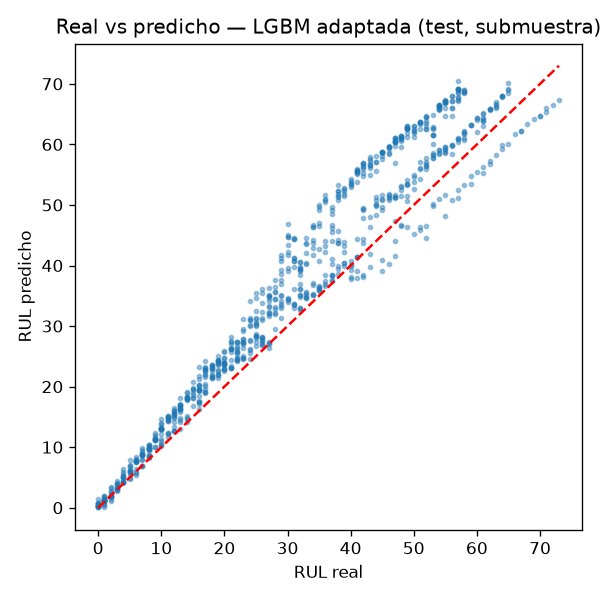

In [14]:
import joblib
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
lgbm = joblib.load('src/clase/models/lgbm_adaptada.joblib')
from src.clase.ventanas_adaptadas import ventanas_adaptadas
v = ventanas_adaptadas()
te, pr = v['test'], lgbm.predict(v['test']['X_tab'])
y = te['y']
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y[::7], pr[::7], s=6, alpha=0.4)
ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — LGBM adaptada (test, submuestra)')
fig.tight_layout(); fig.savefig('resultados/lgbm_adapt_real_vs_pred.png', dpi=120); plt.close(fig)
mu = te['meta'].copy(); mu['pred'] = pr; mu['y'] = y
tab = mu.groupby('unit').apply(lambda g: pd.Series({'rmse': float(np.sqrt(np.mean((g['y']-g['pred'])**2))), 'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: el error concentra en U14 (pocas ventanas de test).')
print('CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; la evidencia completa del bundle desplegado está en el NB06.')
from IPython.display import Image, display
display(Image('resultados/lgbm_adapt_real_vs_pred.png'))


## Cierre

- NB04 valida el camino: misma partición, mismo grano, mismo contrato; coste del MAR ≈ 0 en tabular.
- Decisión NB05 tomada: bundle C (BiLSTM+stacking+EMA) desplegado en `models/`.


## Siguiente
Continúa en `06_evaluacion_produccion_comparativa.ipynb`.


## Defensa — dónde vive el train oficial (solo Markdown)

> **Esta celda es texto Markdown añadido para la defensa; no se ha ejecutado nada y no cambia código, outputs ni `execution_count`.**

- **Entreno oficial de la LGBM adaptada:** `src/clase/train_lgbm_adaptada.py:34` `entrenar()` (escribe `resultados/comparativa_ventanas.csv:60` + `src/clase/models/lgbm_adaptada.joblib:61`).
- **NB05 NO lo invoca.** La celda 30 (0-based, `exec=11`; en 1-based es la 31) duplica ese `fit` en vivo *sin escribir CSV ni joblib* y hace `assert` contra el CSV. La celda 29 es Markdown de procedencia.
- El **bundle C** tampoco se entrena aquí: `src/ds02_rul/bundle_c.py:entrenar` vía `src/ds02_rul/persistence.py:202` — **NB05 NO lo invoca**; recarga `notebooks/artifacts_c/` de NB04 (celda 6) y carga el joblib oficial en la 38.
- Aviso de 20 s: «LGBM en vivo: mismo código que el `.py` pero sin escribir; el modelo vive solo en esta celda y se ancla contra el CSV.»


In [15]:
# --- MLflow live: multisemilla (seed_rows / summary / per_seed) ---
from ds02_rul.mlflow_live import log_live_run, persist_timings
_summary = globals().get("summary"); _per_seed = globals().get("per_seed", [])
_timing_rows = []
if _summary is not None:
    for _label in ["LightGBM solo", "BiLSTM solo", "Híbrido + EMA5"]:
        _sub = _summary[_summary.Modelo == _label]
        if len(_sub):
            _sub = _sub.iloc[0]
            _key = f"live__nb05_{_label.replace(' ', '_').replace('+', 'plus')}"
            log_live_run(_key,
                         params={"notebook": "05", "seeds": "42,7,123", "window": 50,
                                 "step_train": 3, "step_test": 2, "epochs": 22},
                         metrics={"rmse_test": float(_sub["RMSE_mean"]),
                                  "rmse_std": float(_sub["RMSE_std"]),
                                  "nasa_test": float(_sub["NASA_Score_mean"])},
                         notebook="05")
for _row in _per_seed:
    _timing_rows.append({"run_key": f"live__nb05_seed_{_row['seed']}",
                         "t_lgb_s": None, "t_bilstm_s": None, "tiempo_s": None,
                         "fuente": "live_notebook"})
persist_timings(_timing_rows, "nb05")
print("[NB05 MLflow live OK]")


[NB05 MLflow live OK]
